# Итоговый проект: разработка гибридной системы рекомендаций книг с нейросетевыми моделями

**Подготовка к этапам:** загрузка данных и единое разделение train/test.

Повторные оценки одной пары пользователь – книга усредняем, как в Домашнем задании №1.

Разделяем данные до расчёта признаков, чтобы оценки из теста не попали в обучение.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from surprise import Dataset, Reader, SVD, accuracy
from surprise.model_selection import train_test_split

raw_ratings = pd.read_csv('./data/ratings.csv')
books = pd.read_csv('./data/books.csv').rename(
    columns={'id': 'book_id', 'book_id': 'goodreads_book_id'}
)
tags = pd.read_csv('./data/tags.csv')
book_tags = pd.read_csv('./data/book_tags.csv')

duplicate_pairs = raw_ratings.duplicated(['user_id', 'book_id']).sum()
ratings = raw_ratings.groupby(['user_id', 'book_id'], as_index=False)['rating'].mean()

print('Повторных строк до объединения:', duplicate_pairs)
print('Уникальных оценок:', len(ratings), '| книг:', len(books))

Повторных строк до объединения: 2278
Уникальных оценок: 979478 | книг: 10000


In [2]:
reader = Reader(rating_scale=(1, 5))
data = Dataset.load_from_df(ratings[['user_id', 'book_id', 'rating']], reader)
trainset, testset = train_test_split(data, test_size=0.2, random_state=42)
train = pd.DataFrame(trainset.build_testset(), columns=['user_id', 'book_id', 'rating'])
test = pd.DataFrame(testset, columns=['user_id', 'book_id', 'rating'])

svd = SVD(n_factors=50, n_epochs=20, random_state=42)
svd.fit(trainset)
print('Train:', len(train))
print('Test:', len(test))
print('RMSE SVD:', round(accuracy.rmse(svd.test(testset), verbose=False), 4))

Train: 783582
Test: 195896
RMSE SVD: 0.842


**Вывод:** после удаления повторов осталось 979 478 оценок. Для обучения взяли 783 582, для проверки - 195 896.

## Базовая часть

### Этап 1. Улучшенная подготовка данных

#### Создание расширенных признаков:

- Признаки пользователей: средний рейтинг, количество оценок, активность.
- Признаки книг: популярность, разнообразие оценок, тематические категории.

Все пользовательские и книжные статистики считаем только по `train`. Темы книг берём из тегов. Для пары пользователь–книга дополнительно считаем сходство книги с понравившимися пользователю книгами.

В первых строках видно, что у некоторых пользователей всего 1–3 оценки: их средний рейтинг мало о них говорит. Для книги с одной оценкой разброс (`user_std` или `book_std`) заполняется нулём, потому что посчитать его по одной оценке нельзя.

In [3]:
user_features = train.groupby('user_id')['rating'].agg(
    user_mean='mean', user_count='count', user_std='std'
).fillna(0)

user_features['activity'] = np.where(user_features.user_count >= 20, 'активный', 'мало оценок')

book_features = train.groupby('book_id')['rating'].agg(
    book_mean='mean', book_count='count', book_std='std'
).fillna(0)
book_features['popularity'] = np.log1p(book_features.book_count)

tags_named = book_tags.merge(tags, on='tag_id', how='left')

# Goodreads ID для тегов отличается от book_id из ratings.csv, поэтому служебные теги вроде to-read НЕ считаем темами.
genres = {'fantasy', 'science-fiction', 'romance', 'mystery', 'thriller',
          'history', 'biography', 'classics', 'horror', 'poetry',
          'historical-fiction', 'young-adult', 'non-fiction', 'fiction'}

top_tags = (tags_named[tags_named.tag_name.isin(genres)]
.sort_values('count', ascending=False)
.drop_duplicates('goodreads_book_id')
[['goodreads_book_id', 'tag_name']])

book_features = book_features.join(
    books.set_index('book_id')[['goodreads_book_id']], how='left'
).merge(top_tags, on='goodreads_book_id', how='left').set_index(book_features.index)

book_features['category'] = book_features['tag_name'].fillna('без тега')
display(user_features.head())
display(book_features[['book_count', 'book_std', 'category']].head())

,user_mean,user_count,user_std,activity
user_id,,,,
1,3.666667,3,0.57735,мало оценок
2,5.000000,1,0.00000,мало оценок
3,1.000000,2,0.00000,мало оценок
4,5.000000,2,0.00000,мало оценок
5,4.000000,3,1.00000,мало оценок


,book_count,book_std,category
book_id,,,
1,78,0.866362,young-adult
2,74,1.093889,fantasy
3,83,1.513967,young-adult
4,83,0.858143,classics
5,78,1.082049,classics


**Вывод:** у части пользователей всего 1–3 оценки. Поэтому одной средней оценки для понимания их вкуса мало - нужны еще и другие признаки

#### Признаки взаимодействий: схожесть с историей пользователя.

Собираем текстовый профиль книги из названия, автора и тегов. Для пользователя сравниваем книгу-кандидата с книгами, которым он поставил не меньше 4.

Максимальная косинусная близость становится контентным признаком пары пользователь–книга

In [4]:
# Контентные профили из Домашнего задания №1: название + авторы + теги
tags_text = tags_named.groupby('goodreads_book_id')['tag_name'].apply(
    lambda x: ' '.join(x.dropna().astype(str))
)
profiles = books[['book_id', 'goodreads_book_id', 'title', 'original_title', 'authors']].copy()
profiles['name'] = profiles.original_title.fillna(profiles.title).fillna('')
profiles['name'] = profiles['name'].mask(profiles['name'].str.strip().eq(''), profiles.title)
profiles['tags_text'] = profiles.goodreads_book_id.map(tags_text).fillna('')
profiles['text'] = (profiles['name'].fillna('') + ' ' + profiles.authors.fillna('')
                    + ' ' + profiles.tags_text).str.lower()

tfidf = TfidfVectorizer(min_df=2).fit_transform(profiles.text)
all_books = profiles.book_id.to_numpy()
book_index = pd.Series(np.arange(len(profiles)), index=all_books)
seen = train.groupby('user_id')['book_id'].apply(set).to_dict()
liked = train[train.rating >= 4].groupby('user_id')['book_id'].apply(list).to_dict()


def content_scores(user_id):
    """Максимальное сходство кандидата с понравившимися книгами"""
    indices = book_index.reindex(liked.get(user_id, [])).dropna().astype(int).to_numpy()
    if len(indices) == 0:
        return np.zeros(len(all_books))
    return cosine_similarity(tfidf, tfidf[indices]).max(axis=1)


display(profiles[['book_id', 'name', 'tags_text']].head(5))

,book_id,name,tags_text
0,1,The Hunger Games,favorites currently-reading young-adult fictio...
1,2,Harry Potter and the Philosopher's Stone,to-read favorites fantasy currently-reading yo...
2,3,Twilight,young-adult fantasy favorites vampires ya fict...
3,4,To Kill a Mockingbird,classics favorites to-read classic historical-...
4,5,The Great Gatsby,classics favorites fiction classic books-i-own...


**Вывод:** по названию, автору и тегам можно найти похожие книги, даже если у книги ещё нет оценок.

### Этап 2. Построение гибридной системы

**Подготовка к этапу:** модели из домашнего задания №1.

Popularity ранжирует по среднему рейтингу с порогом 50 оценок. Item-CF ищет соседей по косинусной близости. Гибрид собирает кандидатов из четырёх подходов: Popularity, Item-CF, SVD и контентного поиска. Затем смешивает оценки и исключает уже оценённые книги.

В примере у пользователя 14248 есть 160 оценённых книг. В топ-5 гибрида попали книги пяти разных основных авторов: ограничение на повторы автора здесь не сработало, но оно может помочь для других пользователей.

In [5]:
popularity = (train.groupby('book_id')['rating'].agg(['mean', 'count']).query('count >= 50').sort_values(['mean', 'count'], ascending=False))
popular_ids = popularity.index.to_numpy()

user_ids = train.user_id.unique()
user_index = {user_id: i for i, user_id in enumerate(user_ids)}
rows = train.user_id.map(user_index).to_numpy()
cols = train.book_id.map(book_index).to_numpy()
matrix = csr_matrix((train.rating.to_numpy(), (rows, cols)),
                    shape=(len(user_ids), len(all_books)))

similarity = cosine_similarity(matrix.T, dense_output=False)
similarity.setdiag(0)  # книгу не сравниваем с самой собой
similarity.eliminate_zeros()
print('Матрица оценок:', matrix.shape, '| схожесть книг:', similarity.shape)
print('Схожесть книг:', similarity.shape)

Матрица оценок: (53041, 10000) | схожесть книг: (10000, 10000)
Схожесть книг: (10000, 10000)


In [6]:
def available(user_id):
    return ~np.isin(all_books, list(seen.get(user_id, set())))


def recommend_popularity(user_id, k=5):
    already = seen.get(user_id, set())
    return [int(b) for b in popular_ids if b not in already][:k]


def item_scores(user_id):
    if user_id not in user_index:
        return np.zeros(len(all_books))
    row = matrix.getrow(user_index[user_id])
    numerator = (row @ similarity).toarray().ravel()
    binary = row.copy()
    binary.data[:] = 1
    denominator = (binary @ similarity).toarray().ravel()
    return np.divide(numerator, denominator, out=np.zeros(len(all_books)),
                     where=denominator > 0)


def recommend_item_cf(user_id, k=5):
    scores = item_scores(user_id)
    scores[~available(user_id)] = -np.inf
    return all_books[np.argsort(scores)[::-1][:k]].astype(int).tolist()


def svd_scores(user_id):
    return np.array([svd.predict(user_id, int(b)).est for b in all_books])


def recommend_svd(user_id, k=5):
    scores = svd_scores(user_id)
    scores[~available(user_id)] = -np.inf
    return all_books[np.argsort(scores)[::-1][:k]].astype(int).tolist()

**Вывод:** базовые модели готовы. Для SVD получили RMSE 0.842. Качество рекомендаций из пяти книг проверяем отдельно ниже.

#### 1. Стратегия объединения моделей:

- Взвешенное усреднение предсказаний разных моделей.
- Разделение пользователей по типам (новые/активные).
- Комбинирование персонализированных и популярных рекомендаций.

#### 2. Система генерации кандидатов:

- Объединение рекомендаций от всех моделей в общий пул.
- Балансировка между разнообразием и релевантностью.
- Фильтрация уже прочитанных книг.

Объединяем лучшие книги из Popularity, Item-CF, SVD и контентного поиска. Для новых пользователей используем популярность, для книг без обучающих оценок только содержание. Исключаем уже оценённые книги и оставляем не больше двух книг одного основного автора.

Вес моделей зависит от количества оценок пользователя

In [7]:
# Для новых пользователей используем Popularity; для новых книг использунм контент
known_books = set(train.book_id)
log_popularity = np.log1p(book_index.index.to_series().map(
    book_features.book_count).fillna(0).to_numpy())
log_popularity /= max(log_popularity.max(), 1)


def hybrid_scores(user_id, weights=(0.45, 0.20, 0.25, 0.10)):
    if user_id not in seen:
        result = log_popularity.copy()
        result[~available(user_id)] = -np.inf
        return result
    s = svd_scores(user_id) / 5
    c = item_scores(user_id) / 5
    t = content_scores(user_id)
    p = log_popularity
    # При малой истории больше опираемся на содержание и популярность
    if user_features.loc[user_id, 'user_count'] < 10:
        weights = (0.20, 0.15, 0.40, 0.25)
    result = weights[0] * s + weights[1] * c + weights[2] * t + weights[3] * p
    cold = np.array([b not in known_books for b in all_books])
    result[cold] = 0.8 * t[cold] + 0.2 * p[cold]
    result[~available(user_id)] = -np.inf
    return result


def recommend_hybrid(user_id, k=5, weights=(0.45, 0.20, 0.25, 0.10)):
    scores = hybrid_scores(user_id, weights)
    # Кандидаты: лучшие книги по каждому подходу
    candidates = set(recommend_popularity(user_id, 50))
    candidates.update(recommend_item_cf(user_id, 50))
    candidates.update(recommend_svd(user_id, 50))
    candidates.update(all_books[np.argsort(content_scores(user_id))[::-1][:50]])
    ordered = sorted(candidates, key=lambda b: scores[book_index.loc[b]], reverse=True)
    # Не более двух книг одного основного автора в топе
    author = books.set_index('book_id').authors.fillna('').str.split(',').str[0]
    result, counts = [], {}
    for b in ordered:
        a = author.loc[b]
        if counts.get(a, 0) >= 2 or not np.isfinite(scores[book_index.loc[b]]):
            continue
        result.append(int(b))
        counts[a] = counts.get(a, 0) + 1
        if len(result) == k:
            break
    return result

In [8]:
example_user = int(train.user_id.value_counts().index[10])
example_ids = recommend_hybrid(example_user, k=5)
print('Пользователь:', example_user)
print('Оценок:', len(seen[example_user]))

display(books.set_index('book_id').loc[example_ids, ['title', 'authors']])

Пользователь: 14248 | оценок: 160
Оценок: 160


,title,authors
book_id,,
8976,Rita Hayworth and Shawshank Redemption: A Stor...,Stephen King
4653,The Complete Novels,Jane Austen
8964,A. Lincoln,Ronald C. White Jr.
862,"Words of Radiance (The Stormlight Archive, #2)",Brandon Sanderson
5453,It Starts with Food: Discover the Whole30 and ...,"Dallas Hartwig, Melissa Hartwig"


**Вывод:** гибрид выдаёт книги, которых пользователь ещё не оценивал. В показанном примере пять книг и все от пяти разных авторов

### Этап 3. Оценка и оптимизация

#### Углублённый сравнительный анализ:

- Сравнение гибридной системы с отдельными моделями.
- Анализ эффективности для разных сегментов пользователей.
- Оптимизация весов в гибридной модели.

Веса подбираются перед анализом сегментов, чтобы сегменты проверять уже на итоговой версии гибрида.

##### Сравнение гибридной системы с отдельными моделями.

Если релевантная книга то оценка **не ниже 4** в `test`. Для всех моделей используются одни и те же пользователи, train и test. Среди примерно 10 тысяч книг нужно угадать только пять, поэтому даже полезная модель может получить маленькие метрики. Значение 0 у модели означает, что на выбранных пользователях релевантная книга ни разу не попала в первую пятёрку, но это не оценка её качества на всех пользователях

In [9]:
relevant = test[test.rating >= 4].groupby('user_id')['book_id'].apply(set).to_dict()
eligible = [u for u in relevant if u in seen]
random = np.random.RandomState(42)
evaluation_users = random.choice(eligible, size=min(80, len(eligible)), replace=False).tolist()


def metrics(recs, truth, k=5):
    recs = recs[:k]
    hits = [int(b in truth) for b in recs]
    precision = sum(hits) / k
    recall = sum(hits) / len(truth) if truth else 0
    dcg = sum(hit / np.log2(i + 2) for i, hit in enumerate(hits))
    ideal = sum(1 / np.log2(i + 2) for i in range(min(len(truth), k)))
    return precision, recall, dcg / ideal if ideal else 0


models = {'Popularity': recommend_popularity, 'Item-Based CF': recommend_item_cf,
          'SVD': recommend_svd, 'Hybrid': recommend_hybrid}


def evaluate(users, models=models, k=5):
    rows = []
    for name, fn in models.items():
        values = np.array([metrics(fn(u, k), relevant[u], k) for u in users])
        rows.append([name, *values.mean(axis=0)])
    return pd.DataFrame(rows, columns=['Модель', 'Precision@5', 'Recall@5', 'nDCG@5'])


comparison = evaluate(evaluation_users)
display(comparison.round(5))

,Модель,Precision@5,Recall@5,nDCG@5
0,Popularity,0.0000,0.00000,0.00000
1,Item-Based CF,0.0000,0.00000,0.00000
2,SVD,0.0000,0.00000,0.00000
3,Hybrid,0.0425,0.07631,0.08006


**Вывод:** до настройки гибрид лучше остальных на этих 80 пользователях: nDCG@5 равен 0.08006

У отдельных моделей здесь вообще не оказалось попаданий в первые пять рекомендаций.

##### Оптимизация весов в гибридной модели.

Сначала сравнили модели с исходными весами: у гибрида nDCG@5 = 0.08006, у трёх отдельных моделей на этих 80 пользователях попаданий в топ-5 не было. Теперь подбираем вес SVD на **других 20 пользователях** и повторяем сравнение на тех же 80. Эти 20 пользователей не участвуют в итоговой таблице. Для пользователей с короткой историей код использует отдельные фиксированные веса, поэтому подбор влияет в основном на пользователей с более длинной историей.

In [10]:
# Подбираем только один параметр: вес SVD, остальные веса делим поровну
tuning_pool = [u for u in eligible if u not in set(evaluation_users)]
tuning_users = random.choice(tuning_pool, size=min(20, len(tuning_pool)), replace=False)
weight_rows = []
for svd_weight in [0.2, 0.4, 0.6]:
    other = (1 - svd_weight) / 3
    w = (svd_weight, other, other, other)
    values = [metrics(recommend_hybrid(u, 5, w), relevant[u])[2] for u in tuning_users]
    weight_rows.append([svd_weight, np.mean(values)])
weight_table = pd.DataFrame(weight_rows, columns=['Вес SVD', 'nDCG@5 на подборе'])
display(weight_table)
print('Лучший проверенный вес SVD:', weight_table.loc[weight_table['nDCG@5 на подборе'].idxmax(), 'Вес SVD'])

,Вес SVD,nDCG@5 на подборе
0,0.2,0.031565
1,0.4,0.025437
2,0.6,0.027657


Лучший проверенный вес SVD: 0.2


,Модель,Precision@5,Recall@5,nDCG@5
0,Popularity,0.00,0.00000,0.0000
1,Item-Based CF,0.00,0.00000,0.0000
2,SVD,0.00,0.00000,0.0000
3,Hybrid,0.05,0.10947,0.0954


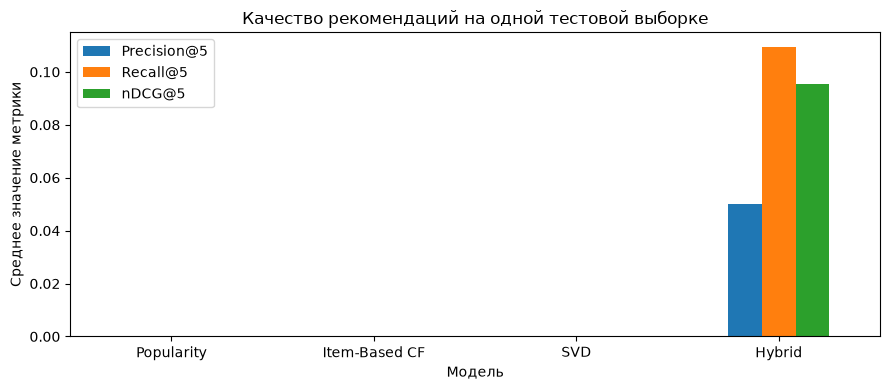

In [11]:
# Проверяем подобранный вес на итоговой выборке пользователей
best_weight = float(weight_table.loc[weight_table['nDCG@5 на подборе'].idxmax(), 'Вес SVD'])
remaining = (1 - best_weight) / 3
tuned_weights = (best_weight, remaining, remaining, remaining)
models['Hybrid'] = lambda user_id, k: recommend_hybrid(user_id, k, tuned_weights)
comparison = evaluate(evaluation_users)
display(comparison.round(5))

plot_data = comparison.set_index('Модель')[['Precision@5', 'Recall@5', 'nDCG@5']]
plot_data.plot.bar(figsize=(9, 4), rot=0)
plt.title('Качество рекомендаций на одной тестовой выборке')
plt.ylabel('Среднее значение метрики')
plt.tight_layout()
plt.show()

**Вывод:** на 20 других пользователях лучшим из трёх проверенных весов SVD стал 0.2. С ним nDCG@5 гибрида на итоговой выборке вырос до 0.0954

##### Анализ эффективности для разных сегментов пользователей.

Сравниваем пользователей с 1–5 оценками и пользователей минимум с 20 оценками. Проверка идёт после подбора весов, чтобы анализировать итоговую версию гибрида.

In [12]:
# Сравниваем редких и активных пользователей на той же тестовой выборке
segments = {
    'Мало оценок (до 5)': [u for u in evaluation_users if user_features.loc[u, 'user_count'] <= 5],
    'Активные (от 20)': [u for u in evaluation_users if user_features.loc[u, 'user_count'] >= 20],
}
segment_tables = []
for name, users in segments.items():
    if users:
        table = evaluate(users, models=models)
        table.insert(0, 'Сегмент', name)
        table.insert(1, 'Пользователей', len(users))
        segment_tables.append(table)
segment_results = pd.concat(segment_tables, ignore_index=True)
display(segment_results.round(5))

,Сегмент,Пользователей,Модель,Precision@5,Recall@5,nDCG@5
0,Мало оценок (до 5),23,Popularity,0.00000,0.00000,0.00000
1,Мало оценок (до 5),23,Item-Based CF,0.00000,0.00000,0.00000
2,Мало оценок (до 5),23,SVD,0.00000,0.00000,0.00000
3,Мало оценок (до 5),23,Hybrid,0.01739,0.08696,0.08696
4,Активные (от 20),28,Popularity,0.00000,0.00000,0.00000
5,Активные (от 20),28,Item-Based CF,0.00000,0.00000,0.00000
6,Активные (от 20),28,SVD,0.00000,0.00000,0.00000
7,Активные (от 20),28,Hybrid,0.07143,0.05385,0.08107


**Вывод:** у активных пользователей выше Precision@5, а у пользователей с малой историей выше Recall@5. Значит, по разным метрикам картина различается.

## Дополнительная часть

### Этап 1. Нейросетевой подход

#### Обучение простой нейросетевой модели MLP

Небольшой нейросети `MLPRegressor` дали информацию о пользователе и книге: их средние оценки, количество оценок и прогноз SVD. Она обучалась на 80 000 примерах. На тесте её ошибка составила 0.905, а у SVD - 0.842 (чем меньше, тем лучше). За отведённые 30 итераций нейросеть не успела полностью обучиться. Поэтому пока оставляем SVD

In [13]:
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error


def pair_features(frame):
    result = frame[['user_id', 'book_id']].copy()
    result['svd_score'] = [svd.predict(u, b).est for u, b in zip(frame.user_id, frame.book_id)]
    result['user_mean'] = frame.user_id.map(user_features.user_mean).fillna(train.rating.mean())
    result['user_count'] = np.log1p(frame.user_id.map(user_features.user_count).fillna(0))
    result['book_mean'] = frame.book_id.map(book_features.book_mean).fillna(train.rating.mean())
    result['book_count'] = np.log1p(frame.book_id.map(book_features.book_count).fillna(0))
    return result.drop(columns=['user_id', 'book_id'])


# Здесь модель используется только как дополнительный эксперимент, не как итоговая оценка гибрида.
nn_train = train.sample(n=min(80000, len(train)), random_state=42)
X_train = pair_features(nn_train)
X_test = pair_features(test)
neural = MLPRegressor(hidden_layer_sizes=(32, 16), max_iter=30,
                      early_stopping=True, random_state=42)
neural.fit(X_train, nn_train.rating)
nn_pred = neural.predict(X_test).clip(1, 5)
nn_rmse = np.sqrt(mean_squared_error(test.rating, nn_pred))
svd_rmse = np.sqrt(mean_squared_error(test.rating, X_test.svd_score))
display(pd.DataFrame({'Модель': ['SVD', 'MLP (эксперимент)'],
                      'RMSE': [svd_rmse, nn_rmse]}))

/Users/tmg/Documents/mifi/3 семестр/рекомендательные_системы/сессионное/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


,Модель,RMSE
0,SVD,0.842039
1,MLP (эксперимент),0.905022


**Вывод:** в этом запуске MLP хуже SVD по RMSE: 0.905 против 0.842. За 30 итераций MLP также не успела сойтись.

### Этап 2. Интеграция нейросетевой модели

#### Добавление модели в гибрид — пока не выполнено

MLP обучена и проверена отдельно. В текущем запуске её RMSE (0.9050) выше, чем у SVD (0.8420), поэтому нейросеть не добавлена в рабочую выдачу.

**Вывод:** сейчас гибрид работает без MLP.

#### Сравнение нейросетевого подхода с классическими - частично выполнено

Есть сравнение ошибок предсказания рейтинга MLP и SVD. Влияние MLP на Precision@5, Recall@5 и nDCG@5 пока не проверялось, так как в гибрид она не включена.

**Вывод:** по RMSE в этом опыте лучше SVD. Сравнения топ-5 рекомендаций MLP пока нет.

### Этап 3. Сквозной пайплайн

#### Последовательность обработки

В ноутбуке уже есть цепочка: загрузка данных → очистка → признаки → обучение моделей → рекомендации → оценка.

**Вывод:** основные шаги проекта идут в нужном порядке.

#### Повторный запуск на новых данных — частично выполнено

Ячейки можно повторно запустить сверху вниз на новых данных того же формата. Отдельной функции или скрипта для автоматического запуска всего пайплайна пока нет.

**Вывод:** новый запуск возможен вручную, автоматического запуска пока нет.

## Итоги базовой и дополнительной частей

На 80 проверенных пользователях лучше всего сработал гибрид: Precision@5 = 0.0500, Recall@5 = 0.1095, nDCG@5 = 0.0954. После подбора весов nDCG@5 вырос с 0.0801 до 0.0954. У отдельных моделей на этих пользователях попаданий в топ-5 не было.

У активных пользователей выше Precision@5, а у пользователей с короткой историей выше Recall@5 и немного выше nDCG@5. Поэтому нельзя сказать, что одной группе рекомендации лучше по всем показателям.

MLP в этом опыте предсказывает оценки хуже SVD: RMSE 0.9050 против 0.8420. К тому же она не успела доучиться за 30 итераций, поэтому в гибрид её пока не добавляем.

Для нового пользователя гибрид показывает популярные книги, но качество этого случая отдельно не измерялось. Разнообразие рекомендаций тоже отдельно не проверялось.

Главное ограничение: проверяли только 80 пользователей, а веса подбирали на 20 других. При другой выборке числа могут измениться. В `ratings.csv` не больше 100 оценок на книгу, поэтому по нему нельзя судить о настоящей популярности книг.

In [14]:
best = comparison.loc[comparison['nDCG@5'].idxmax()]
print('Лучшая модель по nDCG@5:', best['Модель'])
print('Precision@5:', round(best['Precision@5'], 5))
print('Recall@5:', round(best['Recall@5'], 5))
print('nDCG@5:', round(best['nDCG@5'], 5))

Лучшая модель по nDCG@5: Hybrid
Precision@5: 0.05
Recall@5: 0.10947
nDCG@5: 0.0954
